В цьому домашньому завданні кожне завдання оцінюється по 10 балів.

 **Завдання 1.** Після перегляду лекцій про поняття функії, вступ до лінійної алгебри і мат. формулювання лін. регресії знайдіть найкращу лінію для прогнозу `charges` за `age` **для некурців** (датафрейм `non_smoker_df`) з допомогою

1. Методу МНК (з використанням тільки `numpy`, без `scikit learn`)

2. Full-Batch градієнтного спуску з `numpy` . Протестуйте 3 різних learning rate і зробіть висновок, який є найкращим виходячи з практик для цього, наведених в лекції. Зверніть увагу, що на вхід треба набір даних дворозміний, для цього можливо треба буде трансформувати Ваші дані X в формат, як був в лекції "Математичне формулювання лінійної регресії". Також, градієнтний спуск в нашому випадку може розходитись з навчальним рейтом 0.1, бо цей рейт в цій задачі завеликий. Спробуйте нижчі рейти.
3. З `scikit-learn.LinearRegression`. Тут зверніть увагу, що вхід `X` має бути двовимірним масивом, тому нам потрібно передати dataframe, а не окрему колонку. Якщо у Вас X - колонка (а у Вас так мало б бути), то можна скористатись `X.to_frame()` щоб конвертувати колонку в датафрейм.

Для кожного методу
- знайдіть і виведіть коефіцієнти моделі
- обчисліть прогнози моделі і збережіть в окрему змінну
- порахуйте точність прогнозу RMSE  

Для градієнтного спуску виведіть графік помилки в залежності від ітерації.

А також побудуйте на одному графіку дані `age` проти `charges` в вигляді діаграми розсіювання і всі три лінії регресії, знайдені кожним з методів (для град. спуску оберіть варіант з тим learning rate, який виявився найкращим).

Зробіть висновки, чи відрізняються результати моделей?
Чи є знайдены параметри моделы близькими до ваших найкращих припущень?

In [180]:
import pandas as pd
medical_df = pd.read_csv('Materials/medical-charges.csv') # замініть на ваш шлях до файлу
non_smoker_df = medical_df[medical_df.smoker == 'no']

In [181]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
pd.set_option('display.max.rows',130)
pd.set_option('display.max.columns',130)
pd.set_option('float_format', '{:.2f}'.format)


In [182]:
#Переглянемо структуру наших данних некурців
non_smoker_df.head(5)

,age,sex,bmi,children,smoker,region,charges
1,18,male,33.77,1,no,southeast,1725.55
2,28,male,33.00,3,no,southeast,4449.46
3,33,male,22.70,0,no,northwest,21984.47
4,32,male,28.88,0,no,northwest,3866.86
5,31,female,25.74,0,no,southeast,3756.62


In [183]:
non_smoker_df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
Index: 1064 entries, 1 to 1336
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1064 non-null   int64  
 1   sex       1064 non-null   object 
 2   bmi       1064 non-null   float64
 3   children  1064 non-null   int64  
 4   smoker    1064 non-null   object 
 5   region    1064 non-null   object 
 6   charges   1064 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 66.5+ KB


In [184]:
non_smoker_df.shape

(1064, 7)

In [185]:
non_smoker_df.describe()

,age,bmi,children,charges
count,1064.00,1064.00,1064.00,1064.00
mean,39.39,30.65,1.09,8434.27
std,14.08,6.04,1.22,5993.78
min,18.00,15.96,0.00,1121.87
25%,26.75,26.32,0.00,3986.44
50%,40.00,30.35,1.00,7345.41
75%,52.00,34.43,2.00,11362.89
max,64.00,53.13,5.00,36910.61


In [186]:
non_smoker_df.columns[non_smoker_df.isnull().any()]

Index([], dtype='object')

In [187]:
print('Нулів в age:', (non_smoker_df['age'] == 0).sum())
print('Нулів в charges:', (non_smoker_df['charges'] == 0).sum())
print('Пропусків в age:', non_smoker_df['age'].isna().sum())
print('Пропусків в charges:', non_smoker_df['charges'].isna().sum())

Нулів в age: 0
Нулів в charges: 0
Пропусків в age: 0
Пропусків в charges: 0


## Загальний опис данних  
Маємо сформований датафрейм чисто некурців, необхідні нам стовці age та charges числові.
Мають по 1064 записи, без пустих і нульових значень.

## Розглянемо дані в колонках age та charges

In [188]:
non_smoker_df.age.value_counts()

age
18    57
19    50
21    26
26    25
28    25
41    25
50    25
48    24
45    24
46    24
58    24
55    24
49    24
54    23
25    23
38    23
52    23
53    23
51    23
57    22
22    22
40    22
24    22
31    22
56    22
59    21
32    21
29    21
44    21
23    21
34    21
20    20
33    20
35    20
39    19
36    19
27    19
47    19
42    19
62    19
30    18
63    18
60    18
61    17
37    16
43    15
64    15
Name: count, dtype: int64

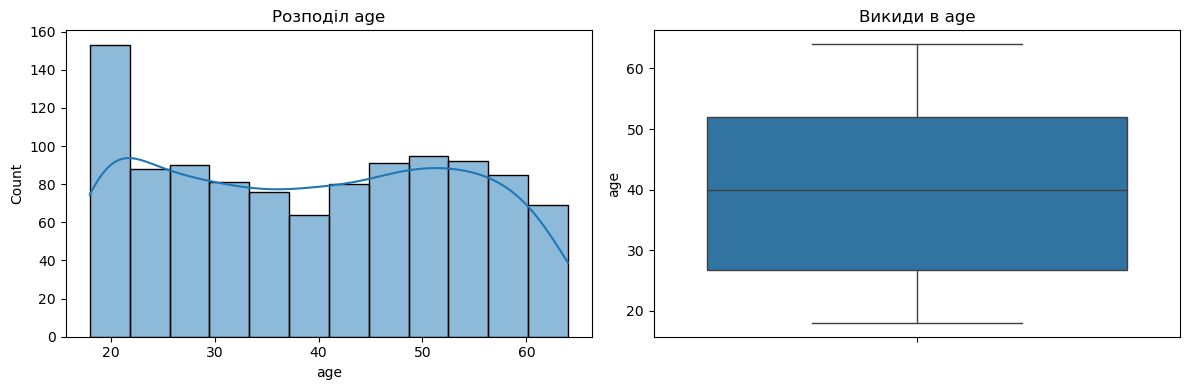

Мода:  18
Середнє:  39.38533834586466
Медіана:  40.0


In [189]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=non_smoker_df, x='age', kde=True, ax=axes[0])
axes[0].set_title('Розподіл age')

sns.boxplot(data=non_smoker_df, y='age', ax=axes[1])
axes[1].set_title('Викиди в age')

plt.tight_layout()
plt.show()

print('Мода: ',non_smoker_df.age.mode()[0])
print('Середнє: ',non_smoker_df.age.mean())
print('Медіана: ',non_smoker_df.age.median())

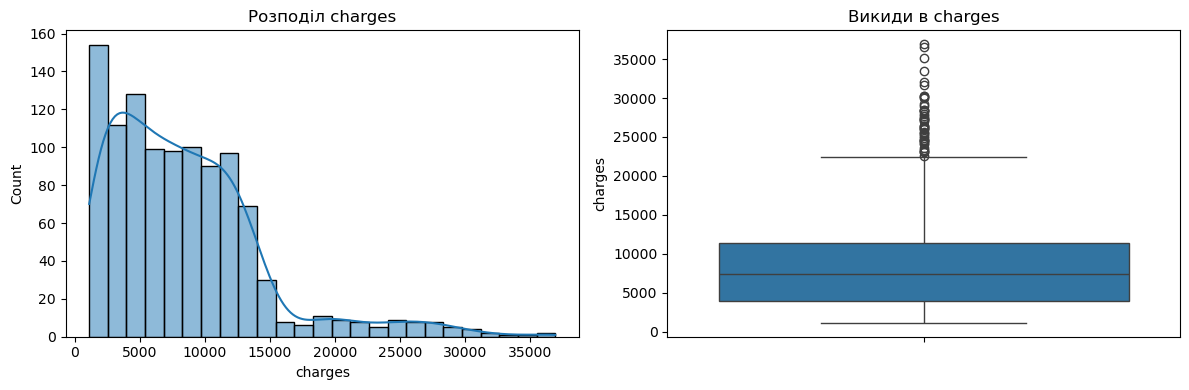

Мода:  1639.5631
Середнє:  8434.268297856204
Медіана:  7345.4053


In [190]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=non_smoker_df, x='charges', kde=True, ax=axes[0])
axes[0].set_title('Розподіл charges')

sns.boxplot(data=non_smoker_df, y='charges', ax=axes[1])
axes[1].set_title('Викиди в charges')

plt.tight_layout()
plt.show()
print('Мода: ',non_smoker_df.charges.mode()[0])
print('Середнє: ',non_smoker_df.charges.mean())
print('Медіана: ',non_smoker_df.charges.median())

## Спостереження
Отже маємо по 1064 значення кожно стовпця, без пропущених значень. 
### Колонка age 
Дані дискретні приймають значення від 18 до 64, в розподілі данних викидів самого значення віку немає, аномальних даних також не спостерігається.  
Бачимо що максимальне значення та мінімальні маюь найбільшу кількість записів, це спостерігається в моді (мода 18, але це не означає що більшість вибірки має 18 років). Середнє і медіана близько одне до одного.  
### Колонка charges  
Основна маса даних розміщена в діапазоні від 1500-2000 до 15000, загальна кількість спостережень з ростом сумми charges зменшується.  
Є довгий хвіст праворуч та викиди: невелика група має суми більше 15000, є окремі значення більше 23000-30000.  
Тобто більшість значень досить невеликі, але є і невелика кількість дуже великих значень, це ми бачимо в моді (1639) та середньому з медіаною (8434 та 7345 відповідно - середнє вище медіани за рахунок естремальних значень).

На даному етапі екстремуми поки не прибираємо, хоча вони можуть давати великі відхилення для МНК, спочатку розглянемо чи є лінійна залежність в наших даних між колонками age та charges

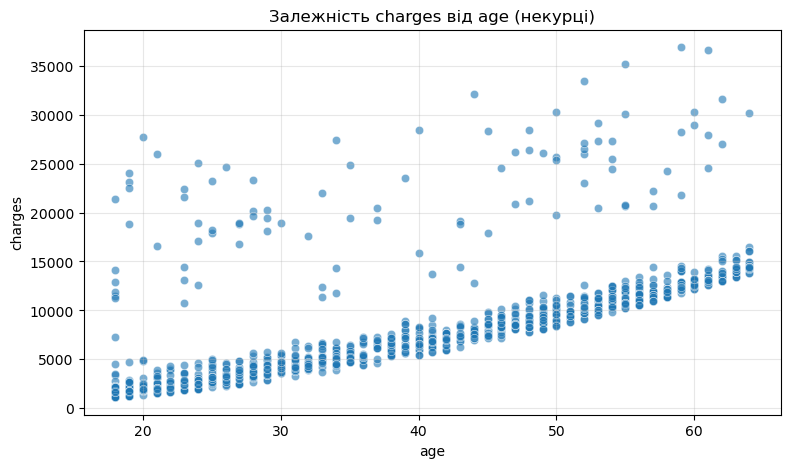

In [191]:
plt.figure(figsize=(9, 5))

sns.scatterplot(data=non_smoker_df, x='age', y='charges', alpha=0.6)

plt.title('Залежність charges від age (некурці)')
plt.xlabel('age')
plt.ylabel('charges')
plt.grid(True, alpha=0.3)
plt.show()

### Спостереження  
По графіку бачимо лінійну залежність що з ростом значеня age ростуть значення charges, але є група спостережень із дуже високими витратами, які суттєво відрізняються від основної маси, при розгляді більшої кількості факторів можливо є певна залежність що при певному значенні інших критеріїв витрати ростуть, але так як ми маємо лише один фактор age, то в даному випадку доцільно прибрати екстремальні значення для побудови функції прогнозу. Для цього використаємо метод IQR

In [192]:
Q1 = non_smoker_df['charges'].quantile(0.25)
Q3 = non_smoker_df['charges'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = non_smoker_df[(non_smoker_df['charges'] < lower_bound) |
    (non_smoker_df['charges'] > upper_bound)]

print('Нижня межа:', lower_bound)
print('Верхня межа:', upper_bound)
print('Кількість потенційних викидів:', len(outliers))
print('Частка викидів:', round(len(outliers) / len(non_smoker_df) * 100, 2), '%')

Нижня межа: -7078.233825
Верхня межа: 22427.559575
Кількість потенційних викидів: 46
Частка викидів: 4.32 %


Формуємо новий дата фрейм з даними без екстремальних значень, так як нижня межа відємна то ми викидуємо лише верхні значення і протестуємо як зміниться прогноз ф повному наборі і без екстремальних значень.

In [193]:
non_smoker_df_clean = non_smoker_df[(non_smoker_df['charges'] <= upper_bound)].copy()

print('Кількість рядків до очищення:', len(non_smoker_df))
print('Кількість рядків після очищення:', len(non_smoker_df_clean))
print('Видалено рядків:', len(non_smoker_df) - len(non_smoker_df_clean))

Кількість рядків до очищення: 1064
Кількість рядків після очищення: 1018
Видалено рядків: 46


### Опис функції та вхідні дані
Загальна функція матиме вигляд 
y = a + b*x  
де x - наші значення age  
y - значення charges  
a, b - наші коефіцієнти в рівнянні що ми будемо передбачати  

Перетворимо наші дані на вектори і додамо до іксів одиничку для пошуку вільного коефіцієнта.


In [194]:
X = non_smoker_df_clean['age'].to_numpy()
y = non_smoker_df_clean['charges'].to_numpy()
X_new = np.c_[np.ones((X.shape[0], 1)), X]

# MNK

In [195]:
#створимо функцію для розрахунку значень коефіцієнтів 
def normal_equations(X,y):
    """Computes the closed-form solution to linear regression"""
    theta = np.linalg.inv(X.T.dot(X)).dot(X.T).dot(y)
    return theta

In [196]:
#Розрахуємо наші коефіцієнти, предікшн функції 
from sklearn.metrics import root_mean_squared_error
MNK_coefs = normal_equations(X_new, y)
predictions_MNK = np.dot(X_new, MNK_coefs)
rmse_MNK = root_mean_squared_error(y, predictions_MNK)

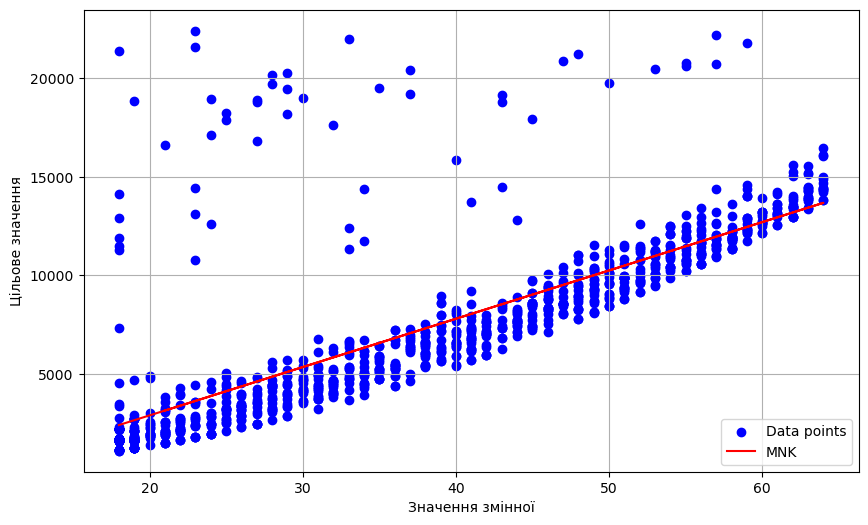

Coef MNK:  [-1982.94698655   244.7151126 ]
RMSE МНК:  2876.2425449980315


In [197]:
# Візуалізація результатів
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', label='Data points')
plt.plot(X, predictions_MNK, color='red', label='MNK')
plt.xlabel('Значення змінної')
plt.ylabel('Цільове значення')
plt.legend()
plt.grid(True)
plt.show()

print('Coef MNK: ', MNK_coefs)
print('RMSE МНК: ', rmse_MNK)

Отримані значення без викидів
Coef MNK:  [-1982.94698655   244.7151126 ]
RMSE МНК:  2876.2425449980315

Отримані значення на повних данних
Coef MNK:  [-2091.42055657   267.24891283]
RMSE МНК:  4662.505766636395

Для порівняння моделей і згладжування викидів щоб не завищувати стандартні значення charges по віку використаємо базу без викидів.

# Full-Batch

m: 193.30232830580226
b: 3.930608346079957
RMSE: 2965.203741730191


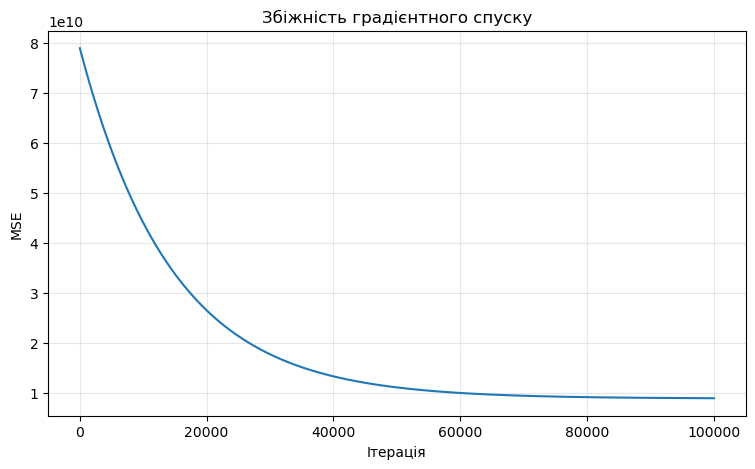

In [198]:
# Градієнтний спуск
def full_batch_gradient_descent(X, y, lr=0.00000001, epochs=100000):
    m, b = 0.0, 0.0  # Початкові параметри
    n = len(y)
    errors = []
    for _ in range(epochs):
        y_pred = m * X + b
        error = y_pred - y
       # print(sum(error)) #- друкування помилок
        errors.append(sum(error**2))
        m_gradient = (2/n) * np.dot(error, X)
        b_gradient = (2/n) * np.sum(error)
        m = m - lr * m_gradient
        b = b - lr * b_gradient
    return m, b, errors

m, b, errors = full_batch_gradient_descent(X, y, lr=0.00000001, epochs=100000)
predictions_fbgd = m * X + b

print('m:', m)
print('b:', b)
print('RMSE:', np.sqrt(np.mean((y - predictions_fbgd)**2)))
# Графік збіжності
plt.figure(figsize=(9, 5))
plt.plot(errors)
plt.xlabel('Ітерація')
plt.ylabel('MSE')
plt.title('Збіжність градієнтного спуску')
plt.grid(True, alpha=0.3)
plt.show()

### Спостереження  
1. при lr=0.00001 - наша функція перескакує і йде в напрямок збільшення помилок і отримуємо не підходящі значення коефіцієнтів та відхилення
m: 199.74602755944971
b: 0.003695825230650411
RMSE: 2953.136118935397

1. при lr=0.000001 - наша функція не сходиться в результаті, потрібно або робити більше ітерацій або збільшувати лернінг рейт
m: 193.33967802467401
b: 3.9314553068088482
RMSE: 2965.066157827379


Одна з причин розбіжності може бути через те що значення x та y мають велику різицю, тому через різні масштаби може бути важко підібрати градієнт. Спробуємо дані стандартизувати.

m: 244.71511255009372
b: -1982.9469845982094
RMSE FB град. спуску:  2876.2425449980315


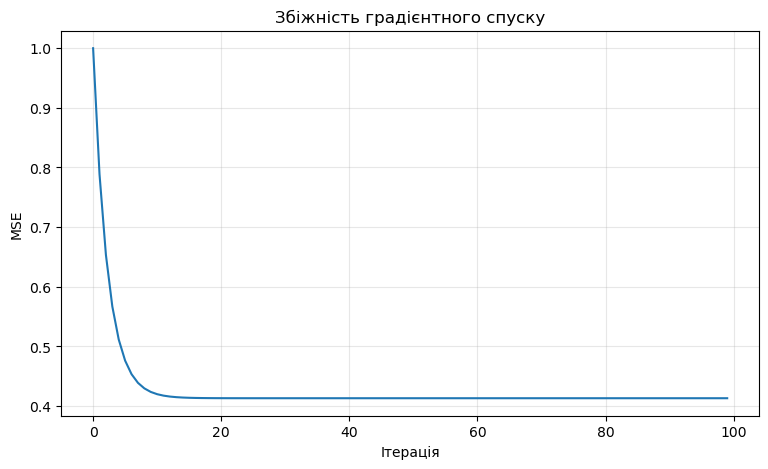

In [199]:
# Стандартизація
X_mean, X_std = X.mean(), X.std()
y_mean, y_std = y.mean(), y.std()

X_scaled = (X - X_mean) / X_std
y_scaled = (y - y_mean) / y_std


def full_batch_gradient_descent(X, y, lr=0.1, epochs=100):
    m, b = 0.0, 0.0
    n = len(y)
    losses = []

    for i in range(epochs):
        y_pred = m * X + b
        error = y_pred - y
       # print(sum(error)) - друкування помилок
        # Середній квадрат помилки
        loss = np.mean(error**2)
        losses.append(loss)

        # Градієнти
        m_gradient = (2 / n) * np.dot(error, X)
        b_gradient = (2 / n) * np.sum(error)

        # Оновлення параметрів
        m -= lr * m_gradient
        b -= lr * b_gradient

    return m, b, losses


m_scaled, b_scaled, losses = full_batch_gradient_descent(X_scaled, y_scaled, lr=0.1, epochs=100)

# Повертаємо коефіцієнти до початкових одиниць
m = m_scaled * y_std / X_std
b = y_mean + y_std * b_scaled - m * X_mean

# Прогноз у початкових одиницях
predictions_fbgd = m * X + b

rmse_fbgd = root_mean_squared_error(y, predictions_fbgd)


print('m:', m)
print('b:', b)
print('RMSE FB град. спуску: ',rmse_fbgd)

# Графік збіжності
plt.figure(figsize=(9, 5))
plt.plot(losses)
plt.xlabel('Ітерація')
plt.ylabel('MSE')
plt.title('Збіжність градієнтного спуску')
plt.grid(True, alpha=0.3)
plt.show()

In [200]:
from sklearn.linear_model import LinearRegression
#імпортування лінійної регресії
# Модель лінійної регресії засобами Scikit-learn (МНК)
X_sl = pd.DataFrame(X, columns=['age'])
lin_reg = LinearRegression()
lin_reg
lin_reg.fit(X_sl, y)


LinearRegression()

In [201]:
#будуємо передбачнення
predictions_sklearn = lin_reg.predict(X_sl)
rmse_sklearn = root_mean_squared_error(y, predictions_sklearn)

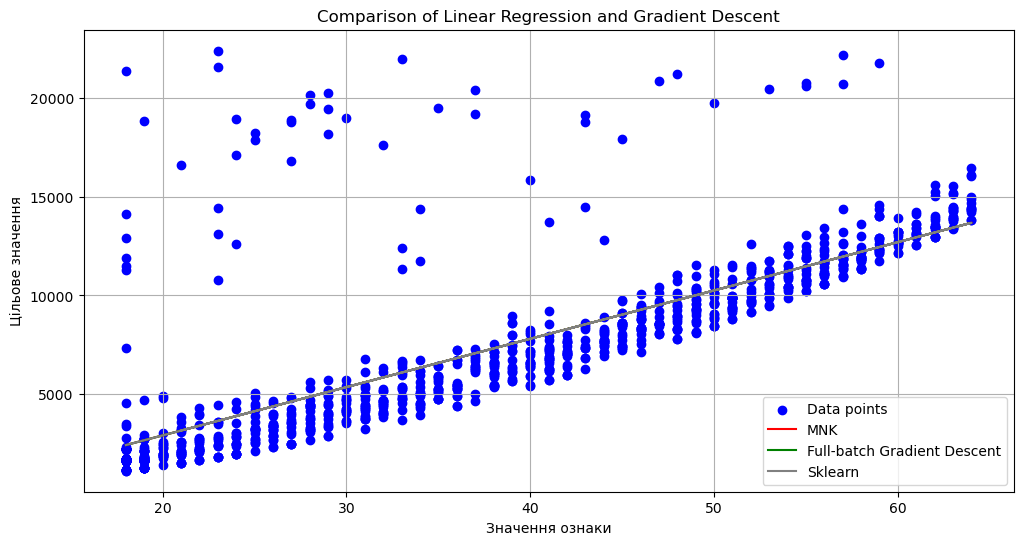

Коефіцієнт: [244.7151126]
Вільний член: -1982.9469865459077
RMSE SL:  2876.2425449980315

Градієнтний спуск FB
m: 244.71511255009372
b: -1982.9469845982094
RMSE FB град. спуску:  2876.2425449980315

MNK
Coef MNK:  [-1982.94698655   244.7151126 ]
RMSE МНК:  2876.2425449980315


In [213]:
# Візуалізація результатів
plt.figure(figsize=(12, 6))
plt.scatter(X, y, color='blue', label='Data points')
plt.plot(X, predictions_MNK, color='red', label='MNK')
plt.plot(X, predictions_fbgd, color='green', label='Full-batch Gradient Descent')
plt.plot(X, predictions_sklearn, color='grey', label='Sklearn')
plt.title('Comparison of Linear Regression and Gradient Descent')
plt.xlabel('Значення ознаки')
plt.ylabel('Цільове значення')
plt.legend()
plt.grid(True)
plt.show()

print('Коефіцієнт:', lin_reg.coef_)
print('Вільний член:', lin_reg.intercept_)
print('RMSE SL: ',rmse_sklearn)
print()
print('Градієнтний спуск FB')
print('m:', m)
print('b:', b)
print('RMSE FB град. спуску: ',rmse_fbgd)
print()
print('MNK')
print('Coef MNK: ', MNK_coefs)
print('RMSE МНК: ', rmse_MNK)

Всі три варіанти зійшлись в одну лінію, якщо б градієнтний спуск ми б не стандартизували наші дані то не отримали б такого чіткого резкльтату. Дані по коефіцієнтам та RMSE відрізняються мінімально.

 **Завдання 2.** Навчіть модель лінійної регресії з допомогою sklearn оцінювати розмір медичних збори для **курців** за їх віком.
Виведіть
- точність моделі
-  коефіцієнти
-  візуалізуйте модель у вигляді лінії на графіку розсіювання `age` проти `charges`

і зробіть висновки, чи це хороша модель, чи ви б її використовували в компанії?

In [205]:
smoker_df = medical_df[medical_df.smoker == 'yes']
smoker_df.shape

(274, 7)

In [206]:
smoker_df.describe()

,age,bmi,children,charges
count,274.00,274.00,274.00,274.00
mean,38.51,30.71,1.11,32050.23
std,13.92,6.32,1.16,11541.55
min,18.00,17.20,0.00,12829.46
25%,27.00,26.08,0.00,20826.24
50%,38.00,30.45,1.00,34456.35
75%,49.00,35.20,2.00,41019.21
max,64.00,52.58,5.00,63770.43


In [207]:
smoker_df.columns[smoker_df.isnull().any()]

Index([], dtype='object')

In [208]:
print('Нулів в age:', (smoker_df['age'] == 0).sum())
print('Нулів в charges:', (smoker_df['charges'] == 0).sum())
print('Пропусків в age:', smoker_df['age'].isna().sum())
print('Пропусків в charges:', smoker_df['charges'].isna().sum())

Нулів в age: 0
Нулів в charges: 0
Пропусків в age: 0
Пропусків в charges: 0


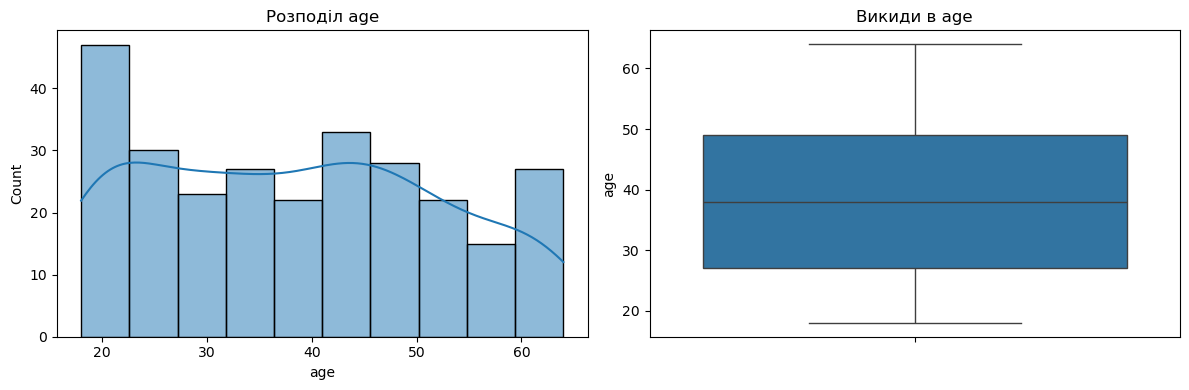

Мода:  19
Середнє:  38.51459854014598
Медіана:  38.0


In [209]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=smoker_df, x='age', kde=True, ax=axes[0])
axes[0].set_title('Розподіл age')

sns.boxplot(data=smoker_df, y='age', ax=axes[1])
axes[1].set_title('Викиди в age')

plt.tight_layout()
plt.show()

print('Мода: ',smoker_df.age.mode()[0])
print('Середнє: ',smoker_df.age.mean())
print('Медіана: ',smoker_df.age.median())

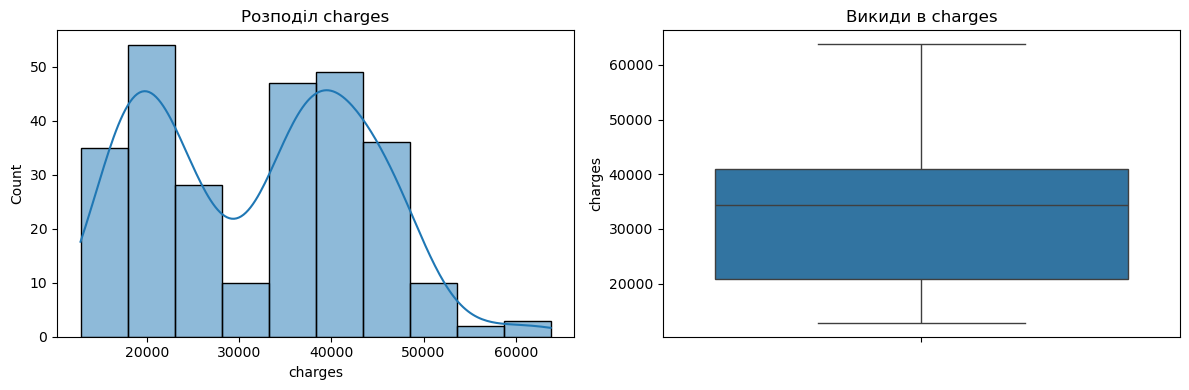

Мода:  12829.4551
Середнє:  32050.23183153284
Медіана:  34456.348450000005


In [210]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=smoker_df, x='charges', kde=True, ax=axes[0])
axes[0].set_title('Розподіл charges')

sns.boxplot(data=smoker_df, y='charges', ax=axes[1])
axes[1].set_title('Викиди в charges')

plt.tight_layout()
plt.show()
print('Мода: ',smoker_df.charges.mode()[0])
print('Середнє: ',smoker_df.charges.mean())
print('Медіана: ',smoker_df.charges.median())

### Спостереження
Отже маємо по 274 значення кожно стовпця, без пропущених значень.

#### Колонка age
Дані дискретні приймають значення від 18 до 64, в розподілі данних викидів самого значення віку немає, аномальних даних також не спостерігається.
Середнє і медіана близько одне до одного.

#### Колонка charges
Для курців суми charges значно вищі і мають більший розкид данних при тому що для курців ми маємо меньшу кількість спостережень. Основна маса даних розміщена в двух піках на рівні 20 000 та 40 000.
Є невеликий хвіст праворуч та можливо викиди, хоча поки не виглядає так що їх варто виключати обовязково.
Медіана вища за середнє значення тому явного впливу викидів не бачу тут.


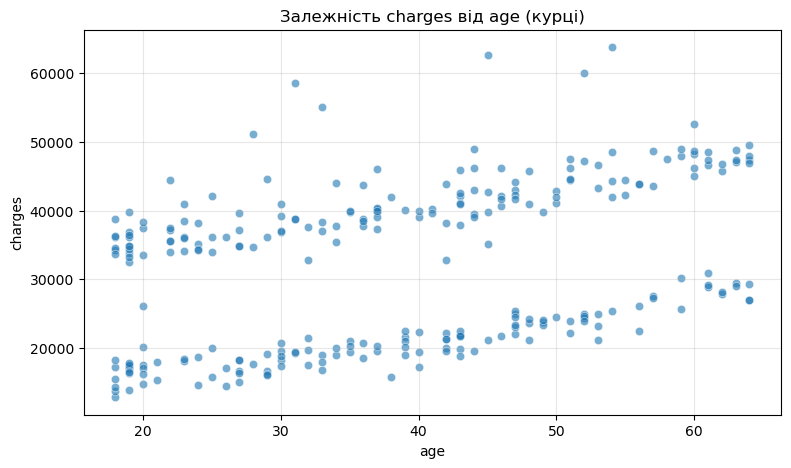

In [212]:
plt.figure(figsize=(9, 5))

sns.scatterplot(data=smoker_df, x='age', y='charges', alpha=0.6)

plt.title('Залежність charges від age (курці)')
plt.xlabel('age')
plt.ylabel('charges')
plt.grid(True, alpha=0.3)
plt.show()

### Спостереження  
З  графіку бачимо що існує певна лінійна залежність для некурців що з ростом віку росте сума charges. Але дані мають два кластери і ми не маємо ознаки по якій можна було б віднести дані до одного чи іншого кластера. Побудуємо по наявним даним функцію лінійної регреії.

In [215]:
X_sm = smoker_df[['age']]
y_sm = smoker_df['charges']
# Модель лінійної регресії засобами Scikit-learn (МНК)

lin_reg_sm = LinearRegression()
lin_reg_sm
lin_reg_sm.fit(X_sm, y_sm)

# Коефіцієнти моделі
print('Коефіцієнт:', lin_reg_sm.coef_)
print('Вільний член:', lin_reg_sm.intercept_)

#будуємо передбачнення
predictions_sklearn_sm = lin_reg_sm.predict(X_sm)
rmse_sklearn_sm = root_mean_squared_error(y_sm, predictions_sklearn_sm)


Коефіцієнт: [305.23760211]
Вільний член: 20294.128126915966


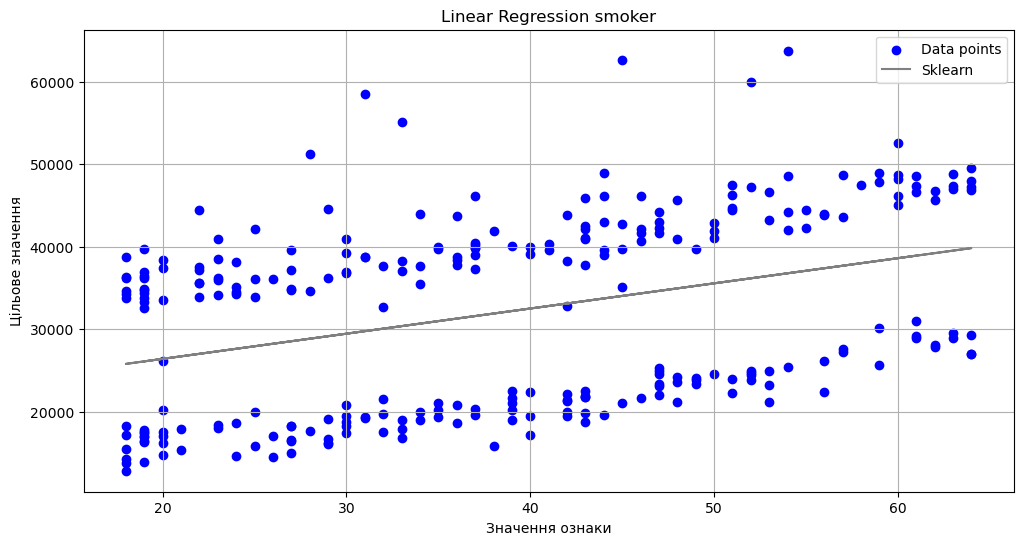

Коефіцієнт: [305.23760211]
Вільний член: 20294.128126915966
RMSE SL:  10711.00334810241


In [216]:
# Візуалізація результатів
plt.figure(figsize=(12, 6))
plt.scatter(X_sm, y_sm, color='blue', label='Data points')
plt.plot(X_sm, predictions_sklearn_sm, color='grey', label='Sklearn')
plt.title('Linear Regression smoker')
plt.xlabel('Значення ознаки')
plt.ylabel('Цільове значення')
plt.legend()
plt.grid(True)
plt.show()

print('Коефіцієнт:', lin_reg_sm.coef_)
print('Вільний член:', lin_reg_sm.intercept_)
print('RMSE SL: ',rmse_sklearn_sm)

Одна регресійна пряма проходить між двома кластерами, тому для верхнього кластера ми систематично занижуємо прогнози, а для нижнього - завищуємо. Тому таку модель  я б не використовувала в роботі. Варто розглянути варіанти приналежності данних до того чи іншого кластеру.